In [1]:
import pandas as pd
df = pd.read_csv('Fraud Detection Dataset.csv')
df

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0
...,...,...,...,...,...,...,...,...,...,...,...,...
50995,T33982,2339,3112.51,Bill Payment,15.0,Mobile,New York,0,7,8,Debit Card,0
50996,T31261,2152,2897.15,Online Purchase,3.0,Mobile,Miami,1,75,11,Net Banking,1
50997,T12293,3345,2204.43,POS Payment,18.0,Mobile,San Francisco,3,73,5,Credit Card,0
50998,T42287,1518,4787.17,POS Payment,19.0,Tablet,New York,2,108,14,Net Banking,0


In [2]:
df.head()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


In [3]:
df.shape

(51000, 12)

In [4]:
df.columns

Index(['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type',
       'Time_of_Transaction', 'Device_Used', 'Location',
       'Previous_Fraudulent_Transactions', 'Account_Age',
       'Number_of_Transactions_Last_24H', 'Payment_Method', 'Fraudulent'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Transaction_ID                    51000 non-null  object 
 1   User_ID                           51000 non-null  int64  
 2   Transaction_Amount                48480 non-null  float64
 3   Transaction_Type                  51000 non-null  object 
 4   Time_of_Transaction               48448 non-null  float64
 5   Device_Used                       48527 non-null  object 
 6   Location                          48453 non-null  object 
 7   Previous_Fraudulent_Transactions  51000 non-null  int64  
 8   Account_Age                       51000 non-null  int64  
 9   Number_of_Transactions_Last_24H   51000 non-null  int64  
 10  Payment_Method                    48531 non-null  object 
 11  Fraudulent                        51000 non-null  int64  
dtypes: f

In [6]:
df.isnull().sum()

Transaction_ID                         0
User_ID                                0
Transaction_Amount                  2520
Transaction_Type                       0
Time_of_Transaction                 2552
Device_Used                         2473
Location                            2547
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Payment_Method                      2469
Fraudulent                             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(881)

In [8]:
df['Fraudulent'].value_counts()

Fraudulent
0    48490
1     2510
Name: count, dtype: int64

In [9]:
df.describe()

,User_ID,Transaction_Amount,Time_of_Transaction,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Fraudulent
count,51000.000000,48480.000000,48448.000000,51000.000000,51000.000000,51000.000000,51000.000000
mean,3005.110176,2996.249784,11.488400,1.995725,60.033902,7.495588,0.049216
std,1153.121107,5043.932555,6.922954,1.415150,34.384131,4.020080,0.216320
min,1000.000000,5.030000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,2007.000000,1270.552500,5.000000,1.000000,30.000000,4.000000,0.000000
50%,2996.000000,2524.100000,12.000000,2.000000,60.000000,7.000000,0.000000
75%,4006.000000,3787.240000,17.000000,3.000000,90.000000,11.000000,0.000000
max,4999.000000,49997.800000,23.000000,4.000000,119.000000,14.000000,1.000000


In [10]:
df = df.drop_duplicates()

In [11]:
df.shape

(50119, 12)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.isnull().sum()

Transaction_ID                         0
User_ID                                0
Transaction_Amount                  2476
Transaction_Type                       0
Time_of_Transaction                 2505
Device_Used                         2437
Location                            2500
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Payment_Method                      2428
Fraudulent                             0
dtype: int64

In [14]:
df['Transaction_Amount'].median()

2523.58

In [15]:
df = df.copy()

In [16]:
df['Transaction_Amount'] = df['Transaction_Amount'].fillna(
    df['Transaction_Amount'].median()
)

In [17]:
df['Transaction_Amount'].isnull().sum()

np.int64(0)

In [18]:
df['Time_of_Transaction'].median()

12.0

In [19]:
df['Time_of_Transaction'] = df['Time_of_Transaction'].fillna(
    df['Time_of_Transaction'].median()
)

In [20]:
df['Time_of_Transaction'].isnull().sum()

np.int64(0)

# Handle categorical missing values

# Deviced_Used

In [21]:
df['Device_Used'].value_counts(dropna=False)

Device_Used
Desktop           15524
Mobile            15321
Tablet            15307
NaN                2437
Unknown Device     1530
Name: count, dtype: int64

# Fill Device_Used

In [22]:
df['Device_Used'] = df['Device_Used'].fillna('Unknown Device')

In [23]:
df['Device_Used'].isnull().sum()

np.int64(0)

# inspect Location

In [24]:
df['Location'].value_counts(dropna=False)

Location
Boston           6037
New York         6003
Seattle          6001
Chicago          5968
Houston          5935
Los Angeles      5910
Miami            5884
San Francisco    5881
NaN              2500
Name: count, dtype: int64

In [25]:
df['Location'] = df['Location'].fillna('Unknown')

In [26]:
df['Location'].isnull().sum()

np.int64(0)

In [27]:
df['Location'].value_counts()

Location
Boston           6037
New York         6003
Seattle          6001
Chicago          5968
Houston          5935
Los Angeles      5910
Miami            5884
San Francisco    5881
Unknown          2500
Name: count, dtype: int64

# Handle Payment_Method 

In [28]:
df['Payment_Method'].value_counts(dropna=False)

Payment_Method
UPI               11671
Debit Card        11614
Net Banking       11462
Credit Card       11417
NaN                2428
Invalid Method     1527
Name: count, dtype: int64

# Fill Missing Payment_Method

In [29]:
df['Payment_Method'] = df['Payment_Method'].fillna('Unknown')

In [30]:
df['Payment_Method'].isnull().sum()

np.int64(0)

In [31]:
df['Payment_Method'].value_counts()

Payment_Method
UPI               11671
Debit Card        11614
Net Banking       11462
Credit Card       11417
Unknown            2428
Invalid Method     1527
Name: count, dtype: int64

# Final missing-value check

In [32]:
df.isnull().sum()

Transaction_ID                      0
User_ID                             0
Transaction_Amount                  0
Transaction_Type                    0
Time_of_Transaction                 0
Device_Used                         0
Location                            0
Previous_Fraudulent_Transactions    0
Account_Age                         0
Number_of_Transactions_Last_24H     0
Payment_Method                      0
Fraudulent                          0
dtype: int64

# Check Data Types

In [33]:
df.dtypes

Transaction_ID                       object
User_ID                               int64
Transaction_Amount                  float64
Transaction_Type                     object
Time_of_Transaction                 float64
Device_Used                          object
Location                             object
Previous_Fraudulent_Transactions      int64
Account_Age                           int64
Number_of_Transactions_Last_24H       int64
Payment_Method                       object
Fraudulent                            int64
dtype: object

# Understand The Target Variable

In [34]:
df['Fraudulent'].value_counts()

Fraudulent
0    47652
1     2467
Name: count, dtype: int64

In [35]:
df['Fraudulent'].value_counts(normalize=True) * 100

Fraudulent
0    95.077715
1     4.922285
Name: proportion, dtype: float64

# First EDA Visualization

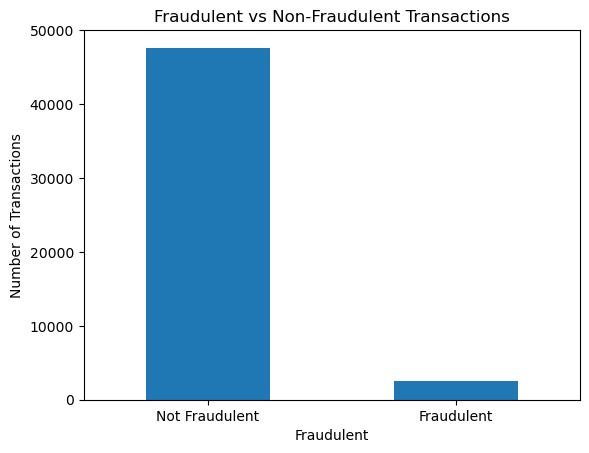

In [36]:
import matplotlib.pyplot as plt

df['Fraudulent'].value_counts().plot(kind='bar')

plt.title('Fraudulent vs Non-Fraudulent Transactions')
plt.xlabel('Fraudulent')
plt.ylabel('Number of Transactions')
plt.xticks(
    [0, 1],
    ['Not Fraudulent', 'Fraudulent'],
    rotation=0
)

plt.show()

# Fraud rate by Transaction Type

In [37]:
df['Transaction_Type'].value_counts()

Transaction_Type
Bill Payment       10161
Bank Transfer      10110
ATM Withdrawal      9979
POS Payment         9957
Online Purchase     9912
Name: count, dtype: int64

In [38]:
# Group transactions by type and calculate statistics
fraud_by_type = df.groupby('Transaction_Type')['Fraudulent'].agg(
    Total_Transactions='count',
    Fraudulent_Transactions='sum'
)

# Calculate the fraud percentage for each type
fraud_by_type['Fraud_Rate_%'] = (
    fraud_by_type['Fraudulent_Transactions']
    / fraud_by_type['Total_Transactions']
) * 100

# Round the percentage to two decimal places
fraud_by_type['Fraud_Rate_%'] = fraud_by_type['Fraud_Rate_%'].round(2)

# Display the summary
fraud_by_type

,Total_Transactions,Fraudulent_Transactions,Fraud_Rate_%
Transaction_Type,,,
ATM Withdrawal,9979,466,4.67
Bank Transfer,10110,487,4.82
Bill Payment,10161,506,4.98
Online Purchase,9912,509,5.14
POS Payment,9957,499,5.01


# Calculate fraud rate by transaction type

In [39]:
df['Transaction_Type'].value_counts()

Transaction_Type
Bill Payment       10161
Bank Transfer      10110
ATM Withdrawal      9979
POS Payment         9957
Online Purchase     9912
Name: count, dtype: int64

In [40]:
df.groupby('Transaction_Type')

# Fraud rates by payment method

In [41]:
fraud_by_payment = df.groupby('Payment_Method')['Fraudulent'].agg(
    Total_Transactions='count',
    Fraudulent_Transactions='sum'
)

fraud_by_payment['Fraud_Rate_%'] = (
    fraud_by_payment['Fraudulent_Transactions']
    / fraud_by_payment['Total_Transactions']
) * 100

fraud_by_payment

,Total_Transactions,Fraudulent_Transactions,Fraud_Rate_%
Payment_Method,,,
Credit Card,11417,562,4.922484
Debit Card,11614,571,4.916480
Invalid Method,1527,73,4.780616
Net Banking,11462,562,4.903158
UPI,11671,596,5.106675
Unknown,2428,103,4.242175


# Fraud rate by device

In [42]:
fraud_by_device = df.groupby('Device_Used')['Fraudulent'].agg(
    Total_Transactions='count',
    Fraudulent_Transactions='sum'
)

fraud_by_device['Fraud_Rate_%'] = (
    fraud_by_device['Fraudulent_Transactions']
    / fraud_by_device['Total_Transactions']
) * 100

fraud_by_device

,Total_Transactions,Fraudulent_Transactions,Fraud_Rate_%
Device_Used,,,
Desktop,15524,738,4.753929
Mobile,15321,791,5.162848
Tablet,15307,714,4.664533
Unknown Device,3967,224,5.646584


# fraud rate by transaction time

In [43]:
df['Time_of_Transaction'].value_counts().head(10)

Time_of_Transaction
12.0    4455
18.0    2071
15.0    2050
13.0    2047
3.0     2023
17.0    2020
0.0     2013
16.0    2011
11.0    1997
1.0     1996
Name: count, dtype: int64

In [44]:
fraud_by_time = df.groupby('Time_of_Transaction')['Fraudulent'].agg(
    Total_Transactions='count',
    Fraudulent_Transactions='sum'
)

fraud_by_time['Fraud_Rate_%'] = (
    fraud_by_time['Fraudulent_Transactions']
    / fraud_by_time['Total_Transactions']
) * 100

fraud_by_time.sort_index()

,Total_Transactions,Fraudulent_Transactions,Fraud_Rate_%
Time_of_Transaction,,,
0.0,2013,92,4.570293
1.0,1996,96,4.809619
2.0,1971,101,5.124302
3.0,2023,95,4.695996
4.0,1991,97,4.871924
5.0,1991,89,4.470116
6.0,1967,102,5.185562
7.0,1951,107,5.484367
8.0,1996,94,4.709419


# plot the hourly fraud rate

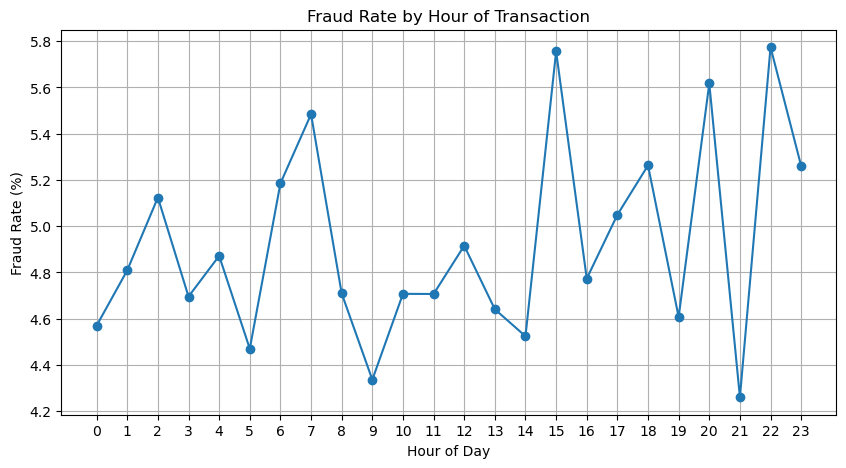

In [45]:
fraud_by_time['Fraud_Rate_%'].plot(
    kind='line',
    marker='o',
    figsize=(10, 5)
)

plt.title('Fraud Rate by Hour of Transaction')
plt.xlabel('Hour of Day')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(24))
plt.grid(True)
plt.show()

# Overall Fraud date

In [50]:
total_transactions = len(df)

fraud_transactions = df["Fraudulent"].sum()

fraud_rate = (
    fraud_transactions / total_transactions
) * 100

print(f"Total transactions: {total_transactions}")
print(f"Fraud transactions: {fraud_transactions}")
print(f"Fraud rate: {fraud_rate:.2f}%")

Total transactions: 50119
Fraud transactions: 2467
Fraud rate: 4.92%


In [49]:
print(df.columns.tolist())

['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type', 'Time_of_Transaction', 'Device_Used', 'Location', 'Previous_Fraudulent_Transactions', 'Account_Age', 'Number_of_Transactions_Last_24H', 'Payment_Method', 'Fraudulent']


In [51]:
hourly = df.groupby("Time_of_Transaction").agg(
    Total_Transactions=("Transaction_ID", "count"),
    Fraudulent_Transactions=("Fraudulent", "sum")
)

hourly["Fraud_Rate_%"] = (
    hourly["Fraudulent_Transactions"]
    / hourly["Total_Transactions"] * 100
)

print(hourly)

                     Total_Transactions  Fraudulent_Transactions  Fraud_Rate_%
Time_of_Transaction                                                           
0.0                                2013                       92      4.570293
1.0                                1996                       96      4.809619
2.0                                1971                      101      5.124302
3.0                                2023                       95      4.695996
4.0                                1991                       97      4.871924
5.0                                1991                       89      4.470116
6.0                                1967                      102      5.185562
7.0                                1951                      107      5.484367
8.0                                1996                       94      4.709419
9.0                                1914                       83      4.336468
10.0                               1933             

In [52]:
print("Total transactions:", hourly["Total_Transactions"].sum())
print("Fraudulent transactions:", hourly["Fraudulent_Transactions"].sum())

Total transactions: 50119
Fraudulent transactions: 2467
